<a href="https://colab.research.google.com/github/Rajsen07/HCL-PROJECT/blob/main/HCL_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please upload auto_mpg.zip when the Choose files button appears


Saving auto+mpg.zip to auto+mpg (1).zip
HEAD:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,origin_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu,USA
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320,USA
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite,USA
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst,USA
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino,USA



TAIL:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,origin_name
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl,USA
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup,Europe
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage,USA
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger,USA
397,31.0,4,119.0,82.0,2720.0,19.4,82,1,chevy s-10,USA



SHAPE: (398, 10)

INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
 9   origin_name   398 non-null    object 
dtypes: float64(5), int64(3), object(2)
memory usage: 31.2+ KB

DESCRIBE:


... (2 outputs left out)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,origin_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto,USA
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick,USA
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe,Europe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra,USA
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i,Europe
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl,USA



===== Q1: MPG Statistics (NumPy) =====
Mean   : 23.51
Median : 23.0
Minimum: 9.0
Maximum: 46.6
Std Dev: 7.81

===== Q2: Average MPG by Cylinders (4, 6, 8) =====
cylinders
4    204
8    103
6     84
3      4
5      3
Name: count, dtype: int64
cylinders
4    29.29
6    19.99
8    14.96
Name: mpg, dtype: float64

===== Q3: Average MPG by Model Year =====
model_year
80    33.70
82    31.71
81    30.33
79    25.09
78    24.06
77    23.38
74    22.70
76    21.57
71    21.25
75    20.27
72    18.71
70    17.69
73    17.10
Name: mpg, dtype: float64

Best year: 1980 with average MPG = 33.70

===== Q4: Top 10 Most Fuel-Efficient Cars =====


,car_name,mpg,cylinders,model_year,origin_name
322,mazda glc,46.6,4,80,Japan
329,honda civic 1500 gl,44.6,4,80,Japan
325,vw rabbit c (diesel),44.3,4,80,Europe
394,vw pickup,44.0,4,82,Europe
326,vw dasher (diesel),43.4,4,80,Europe
244,volkswagen rabbit custom diesel,43.1,4,78,Europe
309,vw rabbit,41.5,4,80,Europe
330,renault lecar deluxe,40.9,4,80,Europe
324,datsun 210,40.8,4,80,Japan
247,datsun b210 gx,39.4,4,78,Japan



===== Q5: Missing Values =====
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
origin_name     0
dtype: int64

Missing horsepower: 6 of 398 rows (1.51%)

===== Q6: Average MPG by Origin =====
origin_name
Japan     30.45
Europe    27.89
USA       20.08
Name: mpg, dtype: float64


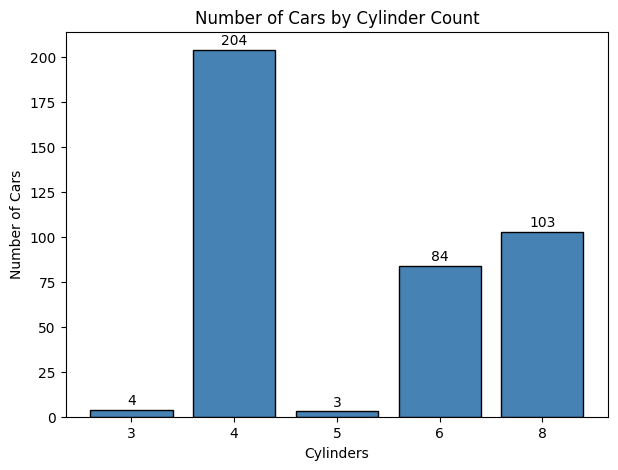

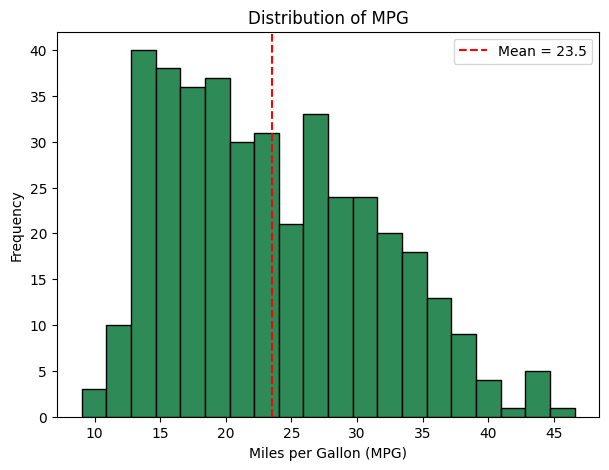


===== 3 OBSERVATIONS =====
1. The average MPG is 23.51 (median 23.0), ranging from 9.0 to 46.6. The histogram is right-skewed: most cars fall in the lower-MPG range.
2. Cylinder count strongly affects efficiency: 4-cylinder cars are the most efficient (29.29 MPG) and 8-cylinder cars the least (14.96 MPG). 4-cylinder and 8-cylinder cars are the most common.
3. Japanese (30.45) and European (27.89) cars average higher MPG than USA cars (20.08). Efficiency also improves over time, with model year 1980 having the highest average MPG.


In [ ]:
# ============================================================
# Auto MPG - Exploratory Data Analysis (EDA)
# ============================================================

# ---------- 1. Import libraries ----------
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ---------- 2. Upload and load the dataset ----------
print("Please upload auto_mpg.zip when the Choose files button appears")
uploaded = files.upload()

name = list(uploaded.keys())[0]
if name.endswith(".zip"):
    with zipfile.ZipFile(name) as z:
        z.extractall("auto_mpg")
    path = "auto_mpg/auto-mpg.data"
else:
    path = name          # works if you upload auto-mpg.data directly

cols = ["mpg", "cylinders", "displacement", "horsepower",
        "weight", "acceleration", "model_year", "origin", "car_name"]

# File has no header; missing horsepower is written as "?"
df = pd.read_csv(path, sep=r"\s+", names=cols, na_values="?", quotechar='"')
df["origin_name"] = df["origin"].map({1: "USA", 2: "Europe", 3: "Japan"})

raw = df.copy()      # keep original (with missing values) for Q5

# ---------- 3. Basic inspection ----------
print("HEAD:")
display(df.head())

print("\nTAIL:")
display(df.tail())

print("\nSHAPE:", df.shape)

print("\nINFO:")
df.info()

print("\nDESCRIBE:")
display(df.describe())

# ---------- 4. Missing values and duplicates ----------
print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nRows with missing horsepower:")
display(df[df["horsepower"].isnull()])

# Fill missing horsepower with the median
df["horsepower"] = df["horsepower"].fillna(df["horsepower"].median())

# ============================================================
# QUESTIONS
# ============================================================

# ---------- Q1. Mean, median, min, max of MPG (NumPy) ----------
mpg_array = df["mpg"].to_numpy()

print("\n===== Q1: MPG Statistics (NumPy) =====")
print("Mean   :", round(np.mean(mpg_array), 2))
print("Median :", np.median(mpg_array))
print("Minimum:", np.min(mpg_array))
print("Maximum:", np.max(mpg_array))
print("Std Dev:", round(np.std(mpg_array), 2))

# ---------- Q2. Average MPG for 4, 6 and 8 cylinders ----------
print("\n===== Q2: Average MPG by Cylinders (4, 6, 8) =====")
print(df["cylinders"].value_counts())
cyl_mpg = (df[df["cylinders"].isin([4, 6, 8])]
           .groupby("cylinders")["mpg"].mean().round(2))
print(cyl_mpg)

# ---------- Q3. Model year with highest average MPG ----------
print("\n===== Q3: Average MPG by Model Year =====")
year_mpg = df.groupby("model_year")["mpg"].mean().round(2).sort_values(ascending=False)
print(year_mpg)
print("\nBest year: 19%d with average MPG = %.2f" % (year_mpg.index[0], year_mpg.iloc[0]))

# ---------- Q4. Top 10 most fuel-efficient cars ----------
print("\n===== Q4: Top 10 Most Fuel-Efficient Cars =====")
top10 = df.sort_values("mpg", ascending=False).head(10)
display(top10[["car_name", "mpg", "cylinders", "model_year", "origin_name"]])

# ---------- Q5. Missing values (horsepower) ----------
print("\n===== Q5: Missing Values =====")
print(raw.isnull().sum())
print("\nMissing horsepower: %d of %d rows (%.2f%%)" %
      (raw["horsepower"].isnull().sum(), len(raw),
       raw["horsepower"].isnull().mean() * 100))

# ---------- Q6. Average MPG by origin ----------
print("\n===== Q6: Average MPG by Origin =====")
origin_mpg = df.groupby("origin_name")["mpg"].mean().round(2).sort_values(ascending=False)
print(origin_mpg)

# ============================================================
# CHARTS
# ============================================================

# ---------- Chart 1: Cylinder-count bar chart ----------
cyl_counts = df["cylinders"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(cyl_counts.index.astype(str), cyl_counts.values,
        color="steelblue", edgecolor="black")
plt.title("Number of Cars by Cylinder Count")
plt.xlabel("Cylinders")
plt.ylabel("Number of Cars")
for i, v in enumerate(cyl_counts.values):
    plt.text(i, v + 3, str(v), ha="center")
plt.show()

# ---------- Chart 2: MPG histogram ----------
plt.figure(figsize=(7, 5))
plt.hist(df["mpg"], bins=20, color="seagreen", edgecolor="black")
plt.axvline(df["mpg"].mean(), color="red", linestyle="--",
            label=f"Mean = {df['mpg'].mean():.1f}")
plt.title("Distribution of MPG")
plt.xlabel("Miles per Gallon (MPG)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# ============================================================
# OBSERVATIONS
# ============================================================
best_cyl = cyl_mpg.idxmax()
worst_cyl = cyl_mpg.idxmin()

print("\n===== 3 OBSERVATIONS =====")
print(f"1. The average MPG is {df['mpg'].mean():.2f} (median {df['mpg'].median():.1f}), "
      f"ranging from {df['mpg'].min()} to {df['mpg'].max()}. "
      f"The histogram is right-skewed: most cars fall in the lower-MPG range.")
print(f"2. Cylinder count strongly affects efficiency: {best_cyl}-cylinder cars are the most "
      f"efficient ({cyl_mpg[best_cyl]} MPG) and {worst_cyl}-cylinder cars the least "
      f"({cyl_mpg[worst_cyl]} MPG). 4-cylinder and 8-cylinder cars are the most common.")
print(f"3. Japanese ({origin_mpg.get('Japan')}) and European ({origin_mpg.get('Europe')}) cars "
      f"average higher MPG than USA cars ({origin_mpg.get('USA')}). "
      f"Efficiency also improves over time, with model year 19{year_mpg.index[0]} "
      f"having the highest average MPG.")